# Alice & Bob cat-qubit challenge: Introductory Track

This notebook reproduces every figure and number in our write-up (`README.md`). The physics
lives in the tested `catqubit` package; the cells here only run simulations and plot them.
Run `pytest` to check the package (97 tests, including the analytic checks quoted below).

Units: $\hbar = 1$, time in µs, rates in rad/µs. Every frequency from the challenge is
converted once, with the $2\pi$, by `catqubit.params.to_angular`.

In [1]:
import math

from pathlib import Path

import dynamiqs as dq
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import json

from catqubit.convergence import fit_decay_rate, smallest_converged
from catqubit.liouvillian import FockTruncation
from catqubit.models import (
    effective_model,
    single_photon_loss_model,
    two_mode_model,
    two_photon_loss_model,
)
from catqubit.observables import (
    cat_coherence,
    fidelity_with,
    memory_state,
    parity_expectation,
    purity,
)
from catqubit.params import CatParams, to_angular
from catqubit.preparation import (
    amplified_push,
    basin_fidelity,
    bias_pulse,
    ramp_push_strength,
    ramped_preparation,
)
from catqubit.rates import phase_flip_rate
from catqubit.simulate import DEFAULT_SOLVER_TOL, inflate
from catqubit.states import cat_state
from catqubit.truncation import top_level_population, top_level_projector

dq.set_precision("double")  # challenge Section 0.5
# Tight ODE tolerance everywhere: see the solver-tolerance check in Task 1.2.
METHOD = dq.method.Tsit5(rtol=DEFAULT_SOLVER_TOL, atol=DEFAULT_SOLVER_TOL)
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

P = CatParams.reglade()
ALPHA2 = P.alpha**2


def real(x):
    return np.real(np.asarray(x))


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")


def wigner_snapshots(states, tsave, times, name, xmax=4.0, nrows=1):
    # Wigner mosaic of states at the requested times, with each frame labelled.
    idx = [int(np.argmin(np.abs(np.asarray(tsave) - s))) for s in times]
    dq.plot.wigner_mosaic(states[jnp.array(idx)], n=len(idx), nrows=nrows, xmax=xmax)
    fig = plt.gcf()
    for ax, i in zip(fig.axes, idx):
        ax.set_title(f"t = {float(tsave[i]):g} µs", fontsize=10)
    # A single row is short, so its title needs more headroom above the frame labels.
    fig.suptitle(rf"Wigner function, $x = \mathrm{{Re}}\,\alpha$ and $p = \mathrm{{Im}}\,\alpha$ in $[-{xmax:g}, {xmax:g}]$",
                 y=1.03 if nrows > 1 else 1.16)
    save(fig, name)
    plt.show()


print(f"g2      = {P.g2:.4f} rad/us")
print(f"kappa_b = {P.kappa_b:.4f} rad/us")
print(f"kappa_a = {P.kappa_a:.5f} rad/us")
print(f"eps_d   = alpha^2 g2 = {P.eps_d:.4f} rad/us")
print(f"kappa2  = 4 g2^2 / kappa_b = {P.kappa2:.4f} rad/us  (kappa2/2pi = {P.kappa2 / (2 * math.pi):.4f} MHz)")

g2      = 4.7941 rad/us
kappa_b = 16.3363 rad/us
kappa_a = 0.05843 rad/us
eps_d   = alpha^2 g2 = 21.1419 rad/us
kappa2  = 4 g2^2 / kappa_b = 5.6275 rad/us  (kappa2/2pi = 0.8956 MHz)


**Wigner axis convention.** `dq.plot.wigner` uses $\hbar = 1/2$ by default, so the axes are
$x = \mathrm{Re}\,\alpha$ and $p = \mathrm{Im}\,\alpha$: a coherent state $|\alpha\rangle$ sits
at $(\mathrm{Re}\,\alpha, \mathrm{Im}\,\alpha)$ and the cat blobs sit at $x = \pm 2.1$.

## Task 1.0(a): single-photon loss in physical units

$\hat H = \Delta\,\hat a^\dagger \hat a$ with $\Delta/2\pi = 1$ MHz, jump $\sqrt{\kappa}\,\hat a$ with
$\kappa/2\pi = 1$ MHz, start in $|\alpha_0 = 2\rangle$, $N = 30$.

max |simulation - analytic| = 5.49e-11 photons


min fidelity with the shrinking coherent state = 1.00000000


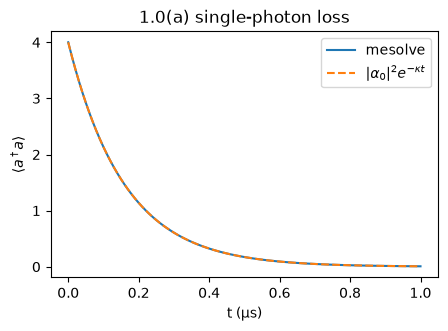

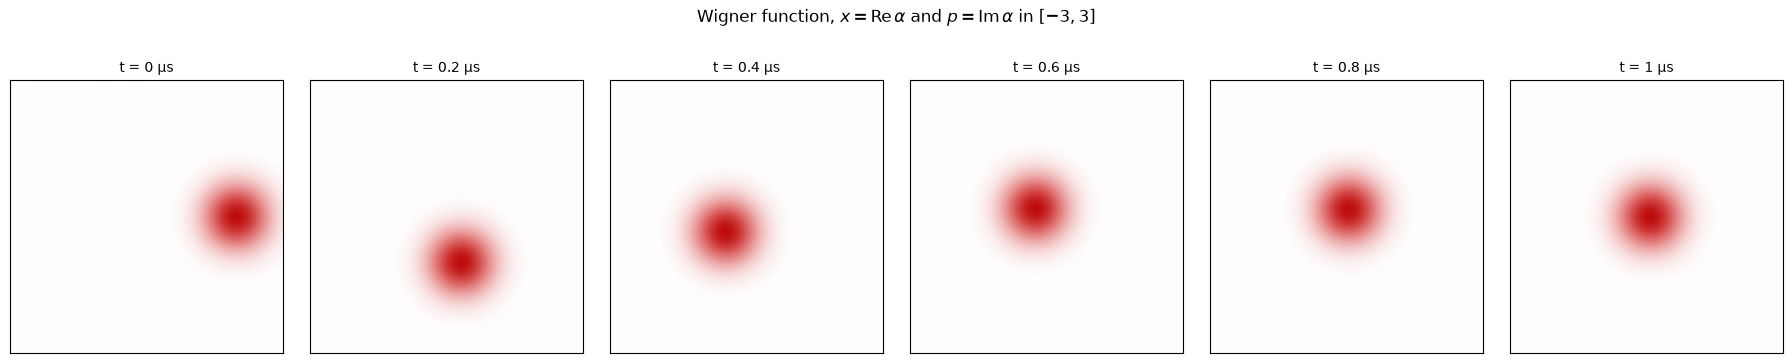

In [2]:
N = 30
KAPPA = to_angular(1.0)
DELTA = to_angular(1.0)
t_a = jnp.linspace(0.0, 1.0, 101)
m = single_photon_loss_model(N, delta=DELTA, kappa=KAPPA)
res_a = dq.mesolve(m.H, m.jump_ops, dq.coherent(N, 2.0), t_a, exp_ops=[dq.number(N)], method=METHOD, progress_meter=False)
n_a0 = real(res_a.expects[0])
analytic = 4.0 * np.exp(-KAPPA * np.asarray(t_a))
print(f"max |simulation - analytic| = {np.max(np.abs(n_a0 - analytic)):.2e} photons")

# "Stays round": compare with the coherent state |2 exp(-i Delta t - kappa t / 2)>.
shrinking = [dq.coherent(N, 2.0 * np.exp((-1j * DELTA - KAPPA / 2) * float(t))) for t in t_a]
fid = [float(fidelity_with(res_a.states[i], k)) for i, k in enumerate(shrinking)]
print(f"min fidelity with the shrinking coherent state = {min(fid):.8f}")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(t_a, n_a0, label="mesolve")
ax.plot(t_a, analytic, "--", label=r"$|\alpha_0|^2 e^{-\kappa t}$")
ax.set(xlabel="t (µs)", ylabel=r"$\langle a^\dagger a\rangle$", title="1.0(a) single-photon loss")
ax.legend()
save(fig, "1_0a_photon_number")
plt.show()
wigner_snapshots(res_a.states, t_a, [0.0, 0.2, 0.4, 0.6, 0.8, 1.0], "1_0a_wigner", xmax=3.0)

The simulation matches $|\alpha_0|^2 e^{-\kappa t}$, and the state stays a coherent state at every
time (fidelity with $|\alpha_0 e^{-i\Delta t - \kappa t/2}\rangle$ printed above). The blob spirals
in once per µs and stays round.

## Task 1.0(b): pure two-photon loss

$\hat H = 0$, single jump $\sqrt{\kappa_2}\,\hat a^2$ with $\kappa_2 = 4g_2^2/\kappa_b$, same initial state.

<n>(3 us)           = 0.499832
(1 - e^-8) / 2       = 0.499832   (initial odd-photon-number population)
final P(|0>), P(|1>) = 0.500168, 0.499832
initial P(|0>) + P(|1>) = 0.0916


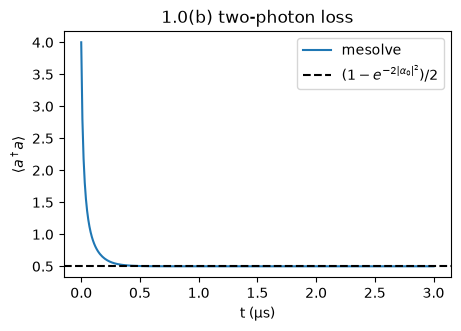

In [3]:
t_b = jnp.linspace(0.0, 3.0, 301)
m = two_photon_loss_model(N, P.kappa2)
res_b = dq.mesolve(m.H, m.jump_ops, dq.coherent(N, 2.0), t_b, exp_ops=[dq.number(N)], method=METHOD, progress_meter=False)
n_b0 = real(res_b.expects[0])
stall = (1 - math.exp(-2 * 2.0**2)) / 2
final_pops = real(jnp.diagonal(res_b.states[-1].to_jax()))
initial_pops = real(jnp.abs(dq.coherent(N, 2.0).to_jax().ravel()) ** 2)
print(f"<n>(3 us)           = {n_b0[-1]:.6f}")
print(f"(1 - e^-8) / 2       = {stall:.6f}   (initial odd-photon-number population)")
print(f"final P(|0>), P(|1>) = {final_pops[0]:.6f}, {final_pops[1]:.6f}")
print(f"initial P(|0>) + P(|1>) = {initial_pops[0] + initial_pops[1]:.4f}")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(t_b, n_b0, label="mesolve")
ax.axhline(stall, ls="--", c="k", label=r"$(1-e^{-2|\alpha_0|^2})/2$")
ax.set(xlabel="t (µs)", ylabel=r"$\langle a^\dagger a\rangle$", title="1.0(b) two-photon loss")
ax.legend()
save(fig, "1_0b_photon_number")
plt.show()

The photon number stalls at **0.4998**, not zero. $\hat a^2$ leaves $|0\rangle$ and $|1\rangle$
untouched, but that is not where the answer comes from: only 9% of the initial state was in those
two levels. What matters is that $\hat a^2$ removes photons **in pairs, so it conserves parity**.
All even-number population ends in $|0\rangle$ and all odd-number population ends in $|1\rangle$,
so the final $\langle n\rangle$ equals the initial odd population,
$(1 - e^{-2|\alpha_0|^2})/2 = 0.49983$. We use this conservation law again in Task 1.3.

## Task 1.0(c): stabilization, and changing the dissipation strength

Jumps $\sqrt{\kappa_2}(\hat a^2 - \alpha^2)$ and $\sqrt{\kappa_a}\,\hat a$, start in vacuum, with
$\kappa_2 \in \{\kappa_2/4,\ \kappa_2,\ 4\kappa_2\}$ in one batched `mesolve` call.

kappa2 x 0.25: <n>(2 us) = 4.3872, t90 = 614.6 ns, t90 * kappa2 = 0.865  (lossless: 0.850)
kappa2 x 1.0 : <n>(2 us) = 4.4040, t90 = 151.7 ns, t90 * kappa2 = 0.854  (lossless: 0.850)
kappa2 x 4.0 : <n>(2 us) = 4.4081, t90 =  37.8 ns, t90 * kappa2 = 0.851  (lossless: 0.851)
monotonic rise (nominal): True


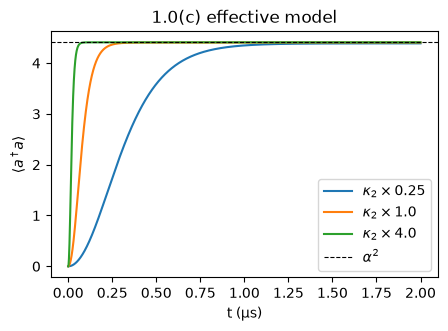

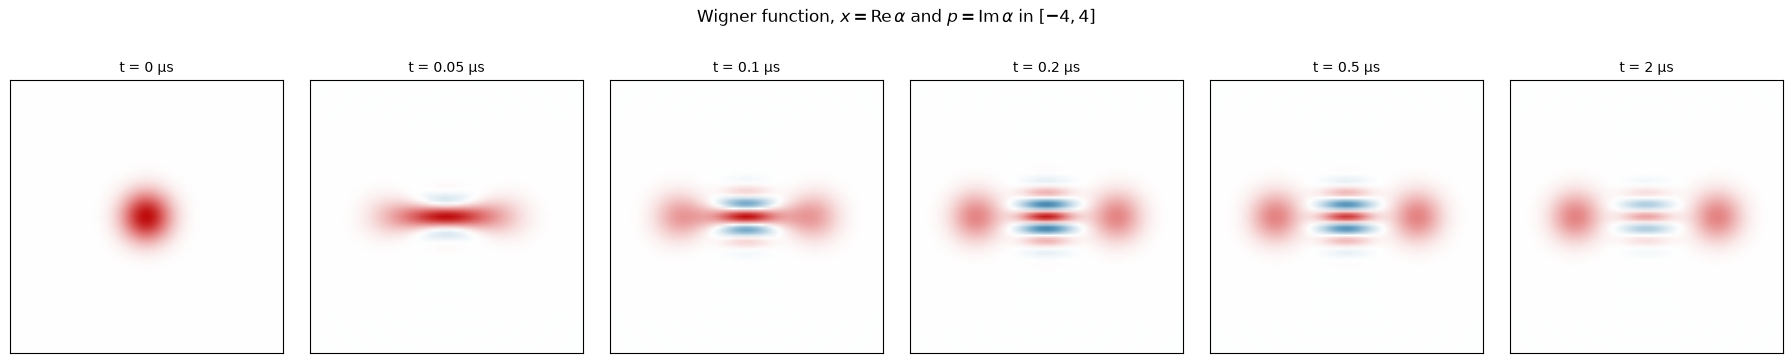

In [4]:
SCALES = [0.25, 1.0, 4.0]
t_c = jnp.linspace(0.0, 2.0, 2001)  # 1 ns steps: t90 at 4 kappa2 is ~40 ns
kappa2s = jnp.array(SCALES) * P.kappa2


def batched_photon_number(params):
    m = effective_model(N, params, kappa2=kappa2s)
    res = dq.mesolve(m.H, m.jump_ops, dq.fock(N, 0), t_c, exp_ops=[dq.number(N)], method=METHOD, progress_meter=False)
    return res, real(res.expects[:, 0, :])


def t90(curve):
    # Interpolated: snapping to the 5 ns grid is a 12% error at 4 kappa2 (t90 ~ 40 ns).
    return float(np.interp(0.9 * ALPHA2, curve, np.asarray(t_c)))


res_c, n_c = batched_photon_number(P)
_, n_c_lossless = batched_photon_number(CatParams(g2=P.g2, kappa_b=P.kappa_b, kappa_a=0.0, alpha=P.alpha))
n_eff_nominal = n_c[1]
for scale, curve, lossless in zip(SCALES, n_c, n_c_lossless):
    print(
        f"kappa2 x {scale:<4}: <n>(2 us) = {curve[-1]:.4f}, t90 = {t90(curve) * 1e3:5.1f} ns, "
        f"t90 * kappa2 = {t90(curve) * scale * P.kappa2:.3f}  (lossless: {t90(lossless) * scale * P.kappa2:.3f})"
    )
print(f"monotonic rise (nominal): {bool(np.all(np.diff(n_eff_nominal) > -1e-9))}")

fig, ax = plt.subplots(figsize=(5, 3.2))
for scale, curve in zip(SCALES, n_c):
    ax.plot(t_c, curve, label=rf"$\kappa_2 \times {scale}$")
ax.axhline(ALPHA2, ls="--", c="k", lw=0.8, label=r"$\alpha^2$")
ax.set(xlabel="t (µs)", ylabel=r"$\langle a^\dagger a\rangle$", title="1.0(c) effective model")
ax.legend()
save(fig, "1_0c_photon_number")
plt.show()
wigner_snapshots(res_c.states[1], t_c, [0.0, 0.05, 0.1, 0.2, 0.5, 2.0], "1_0c_wigner")

All three curves rise monotonically to the same value, $\approx\alpha^2$; only the speed changes.
**Why the speed is exactly $\propto 1/\kappa_2$ when $\kappa_a = 0$:** the master equation is then
$\dot\rho = \kappa_2\,\mathcal D_{\hat a^2 - \alpha^2}[\rho]$, so $\kappa_2$ is the only rate and
$\rho(t)$ depends on $t$ only through $\kappa_2 t$. The lossless column confirms it: $t_{90}\kappa_2$ is
0.850, 0.850 and 0.851 for the three $\kappa_2$ (the 0.1% spread is the 1 ns time grid). With
$\kappa_a \ne 0$ a second rate enters, so the collapse is only approximate. It is worst at $\kappa_2/4$
(0.865), where $\kappa_a/\kappa_2$ is largest. The settling value also drops slightly at small $\kappa_2$
(4.387 vs 4.404), for the same reason; see the mean-field estimate in Task 1.2.

## Task 1.1 at the suggested truncation ($N_a = 24$, $N_b = 6$)

First, the full two-mode model at the suggested starting truncation, *with the truncation monitor on*.

In [5]:
t_1 = jnp.linspace(0.0, 3.0, 301)
res_s = inflate(24, 6, P, t_1)
na_s, nb_s = real(res_s.expects)
top_a_s = real(top_level_population(res_s.states, (24, 6), 0, 2))
top_b_s = real(top_level_population(res_s.states, (24, 6), 1, 1))
print(f"peak <a^dag a> = {na_s.max():.3f} at t = {float(t_1[na_s.argmax()]) * 1e3:.0f} ns, <a^dag a>(3 us) = {na_s[-1]:.4f}")
print(f"peak <b^dag b> = {nb_s.max():.3f}")
print(f"max population in top 2 memory levels = {top_a_s.max():.1e}")
print(f"max population in top buffer level    = {top_b_s.max():.1e}  <-- not negligible")

peak <a^dag a> = 6.115 at t = 230 ns, <a^dag a>(3 us) = 4.4026
peak <b^dag b> = 1.887
max population in top 2 memory levels = 7.9e-05
max population in top buffer level    = 4.6e-02  <-- not negligible


The buffer's top Fock level holds several percent of the population during the transient, so
$N_b = 6$ is **not** converged, even though the steady state looks fine. Task 1.2 quantifies this
before we produce the final Task 1.1 figures.

## Task 1.2: convergence study

We vary $N_a$ and $N_b$ separately, holding the other at the largest value we test, so one
truncation's error does not hide the other's. Two quantities: the steady-state
$\langle a^\dagger a\rangle$ (at $t = 3$ µs) and the transient peak of $\langle a^\dagger a\rangle$.
Time step 5 ns, so the peak is resolved. Tolerance: relative $10^{-3}$ against the largest truncation.

In [6]:
RTOL = 1e-3
T_SWEEP = jnp.linspace(0.0, 3.0, 601)
NA_SWEEP, NB_FIXED = [16, 20, 24, 28, 32], 14
NB_SWEEP, NA_FIXED = [4, 6, 8, 10, 12, 14], 32


def sweep_point(na, nb):
    monitors = [top_level_projector((na, nb), 0, 2), top_level_projector((na, nb), 1, 1)]
    res = inflate(na, nb, P, T_SWEEP, extra_exp_ops=monitors, save_states=False)
    n_a, _, top_a, top_b = real(res.expects)
    return {"steady": n_a[-1], "peak": n_a.max(), "top_a": top_a.max(), "top_b": top_b.max()}


def report(label, sizes, rows):
    print(f"{label:>4} | steady <n_a>  | peak <n_a> | max top-2 memory | max top buffer")
    for size, row in zip(sizes, rows):
        print(f"{size:>4} | {row['steady']:.6f}   | {row['peak']:.5f}    | {row['top_a']:.1e}          | {row['top_b']:.1e}")
    for quantity in ("steady", "peak"):
        values = [row[quantity] for row in rows]
        print(f"  {quantity:>6}: converged (rtol {RTOL:g}) from {label} = {smallest_converged(sizes, values, RTOL)}")


rows_na = [sweep_point(na, NB_FIXED) for na in NA_SWEEP]
report("N_a", NA_SWEEP, rows_na)
print()
rows_nb = [sweep_point(NA_FIXED, nb) for nb in NB_SWEEP]
report("N_b", NB_SWEEP, rows_nb)

 N_a | steady <n_a>  | peak <n_a> | max top-2 memory | max top buffer
  16 | 4.405889   | 6.36550    | 5.7e-02          | 1.2e-03
  20 | 4.402673   | 6.80347    | 1.3e-02          | 4.6e-04
  24 | 4.402636   | 6.89641    | 2.0e-03          | 1.5e-04
  28 | 4.402635   | 6.90957    | 2.5e-04          | 4.0e-05
  32 | 4.402635   | 6.91083    | 2.3e-05          | 1.9e-05
  steady: converged (rtol 0.001) from N_a = 16
    peak: converged (rtol 0.001) from N_a = 28



 N_b | steady <n_a>  | peak <n_a> | max top-2 memory | max top buffer
   4 | 4.402649   | 4.46203    | 6.8e-08          | 1.9e-01
   6 | 4.402634   | 6.11429    | 1.6e-08          | 4.6e-02
   8 | 4.402634   | 6.74415    | 2.0e-07          | 8.6e-03
  10 | 4.402635   | 6.88646    | 3.1e-06          | 1.3e-03
  12 | 4.402635   | 6.90843    | 1.4e-05          | 1.7e-04
  14 | 4.402635   | 6.91083    | 2.3e-05          | 1.9e-05
  steady: converged (rtol 0.001) from N_b = 4
    peak: converged (rtol 0.001) from N_b = 12


converged truncation for both quantities: N_a = 28, N_b = 12


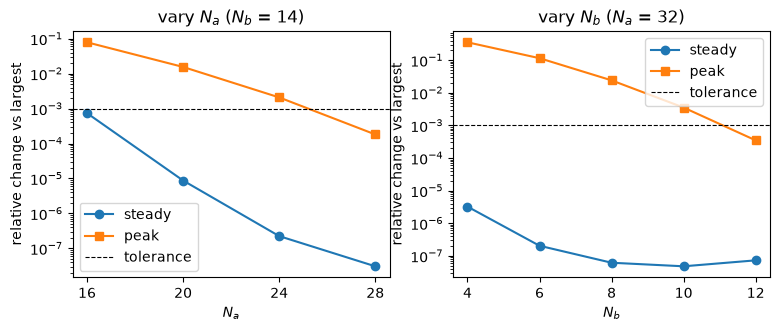

In [7]:
NA_C = max(smallest_converged(NA_SWEEP, [r[q] for r in rows_na], RTOL) for q in ("steady", "peak"))
NB_C = max(smallest_converged(NB_SWEEP, [r[q] for r in rows_nb], RTOL) for q in ("steady", "peak"))
print(f"converged truncation for both quantities: N_a = {NA_C}, N_b = {NB_C}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, sizes, rows, label in [(axes[0], NA_SWEEP, rows_na, "$N_a$"), (axes[1], NB_SWEEP, rows_nb, "$N_b$")]:
    ref = rows[-1]
    for q, marker in (("steady", "o"), ("peak", "s")):
        err = [max(abs(r[q] / ref[q] - 1), 1e-9) for r in rows[:-1]]
        ax.semilogy(sizes[:-1], err, marker=marker, label=q)
    ax.axhline(RTOL, ls="--", c="k", lw=0.8, label="tolerance")
    ax.set(xlabel=label, ylabel="relative change vs largest", xticks=sizes[:-1])
    ax.legend()
axes[0].set_title(f"vary $N_a$ ($N_b$ = {NB_FIXED})")
axes[1].set_title(f"vary $N_b$ ($N_a$ = {NA_FIXED})")
save(fig, "1_2_convergence")
plt.show()

**Result.** At a tolerance of $10^{-3}$, relative to the largest truncation:

| Quantity | Converged from $N_a$ | Converged from $N_b$ |
|---|---|---|
| steady-state $\langle a^\dagger a\rangle$ | 16 (and every larger value tested) | 4 (and every larger value tested) |
| transient peak of $\langle a^\dagger a\rangle$ | **28** | **12** |

**The steady state and the transient are not equally sensitive.** The steady state is insensitive to
both truncations. Even $N_b = 4$ gets it right to $10^{-5}$, because in steady state the buffer is
essentially empty ($\langle b^\dagger b\rangle \approx 2\times10^{-5}$) and the memory holds a cat of 4.4 photons.
The overshoot is far more demanding. $N_b$ matters most: during the transient the buffer briefly holds
about 2 photons and its distribution has a long tail. When the buffer is truncated it cannot hold the
pair-converted energy, so the memory is pumped less and **the overshoot is underestimated**: 4.46 at
$N_b = 4$, 6.11 at the suggested $N_b = 6$ (11.5% low), and 6.91 converged. $N_a$ matters for the peak
because, at 6.9 photons, the memory distribution reaches well beyond the 24 levels that are plenty
in steady state.

**Answer to the hint:** the suggested $N_b = 6$ is the truncation that is too small. It gets the steady
state right but the transient wrong, and the truncation monitor shows it directly (4.6% population
in the top buffer level).

### Solver tolerance is part of convergence too

Our first sweep used dynamiqs' default ODE tolerance (`rtol = atol = 1e-6`). At $N_a = 32$, the
*largest* and supposedly most accurate truncation, it showed **more** population in the top memory
levels than $N_a = 28$, and some of that "population" was negative. That cannot be truncation error,
so we reran the reference point at both tolerances. All results in this notebook use $10^{-9}$.

In [8]:
na, nb = NA_SWEEP[-1], NB_SWEEP[-1]
monitors = [top_level_projector((na, nb), 0, 2), top_level_projector((na, nb), 1, 1)]
for tol in (1e-6, DEFAULT_SOLVER_TOL):
    res = inflate(na, nb, P, T_SWEEP, extra_exp_ops=monitors, save_states=False, solver_tol=tol)
    n_a, _, top_a, top_b = real(res.expects)
    print(f"N_a={na}, N_b={nb}, tol={tol:g}: steady {n_a[-1]:.6f}, peak {n_a.max():.5f}, "
          f"top-2 memory max {top_a.max():.1e} (min {top_a.min():+.1e}), top buffer max {top_b.max():.1e}")

N_a=32, N_b=14, tol=1e-06: steady 4.402524, peak 6.91080, top-2 memory max 1.4e-03 (min -1.2e-03), top buffer max 1.3e-04


N_a=32, N_b=14, tol=1e-09: steady 4.402635, peak 6.91083, top-2 memory max 2.3e-05 (min -1.3e-06), top buffer max 1.9e-05


At the default tolerance the reference run's steady state is off by $2.5\times10^{-5}$ relative, and
the "population" in the top memory levels swings between $\pm 1.4\times10^{-3}$, *larger* than the true
physical value of $2\times10^{-5}$. That would make $N_a = 32$ look less converged than $N_a = 28$. At
$10^{-9}$ the runtime is the same and the monitor is clean. `catqubit.simulate.inflate` now defaults to
$10^{-9}$, and a regression test (`test_inflate_does_not_leak_population_into_top_levels_through_solver_error`)
pins this behavior.

### Semiclassical check: is the small offset from $\alpha^2$ physical?

We compare the converged steady state with $\alpha^2 = \epsilon_d/g_2 = 4.41$, then switch off
$\kappa_a$ as a control: with no memory loss the steady state should be the even cat, with
$\langle n\rangle = \alpha^2\tanh\alpha^2$ exactly.

In [9]:
steady = rows_nb[-1]["steady"]
lossless = CatParams(g2=P.g2, kappa_b=P.kappa_b, kappa_a=0.0, alpha=P.alpha)
steady_lossless = real(inflate(NA_C, NB_C, lossless, T_SWEEP, save_states=False).expects)[0, -1]
print(f"converged steady state <n_a>      = {steady:.5f}  ({(steady / ALPHA2 - 1) * 100:+.2f}% vs alpha^2)")
print(f"same with kappa_a = 0             = {steady_lossless:.5f}")
print(f"alpha^2 tanh(alpha^2) (even cat)  = {ALPHA2 * math.tanh(ALPHA2):.5f}")
print(f"shift from kappa_a                = {steady - steady_lossless:+.5f}")
print(f"mean-field estimate -kappa_a/(2 kappa2) = {-P.kappa_a / (2 * P.kappa2):+.5f}")

converged steady state <n_a>      = 4.40263  (-0.17% vs alpha^2)
same with kappa_a = 0             = 4.40870
alpha^2 tanh(alpha^2) (even cat)  = 4.40870
shift from kappa_a                = -0.00606
mean-field estimate -kappa_a/(2 kappa2) = -0.00519


The converged steady state is 0.17% below $\alpha^2$, well within "a few percent", and the offset is
**physical, not numerical**: it does not move with $N_a$, $N_b$ or solver tolerance. Two effects
account for all of it:

1. **Finite cat size** (0.03%): the steady state is a cat, not a coherent state, and the even cat
   has $\langle n\rangle = \alpha^2\tanh\alpha^2 = 4.40870$. With $\kappa_a = 0$ the two-mode simulation gives
   exactly this, to 5 digits.
2. **Memory loss** (0.14%): single-photon loss pulls the amplitude below the drive's fixed point.
   Mean field for the effective model, $\dot\alpha = -\kappa_2\alpha^*(\alpha^2 - \alpha_\infty^2) - \tfrac{\kappa_a}{2}\alpha$,
   gives $|\alpha|^2 = \alpha_\infty^2 - \kappa_a/(2\kappa_2)$, a shift of $-0.0052$. The two-mode simulation
   gives $-0.0061$; the remaining difference is the non-adiabatic buffer (see Task 1.1).

## Task 1.1 at the converged truncation

All figures below use the converged $N_a$, $N_b$ from Task 1.2.

peak <a^dag a> = 6.894 at t = 230 ns
<a^dag a> stays within 1% of alpha^2 from t = 1.07 us; <a^dag a>(3 us) = 4.4026
peak <b^dag b> = 1.992 at t = 130 ns, <b^dag b>(3 us) = 1.8e-05
max top-2 memory population = 2.2e-04, max top buffer population = 1.8e-04
adiabatic condition: g2/kappa_b = 0.293, eps_d/kappa_b = 1.294


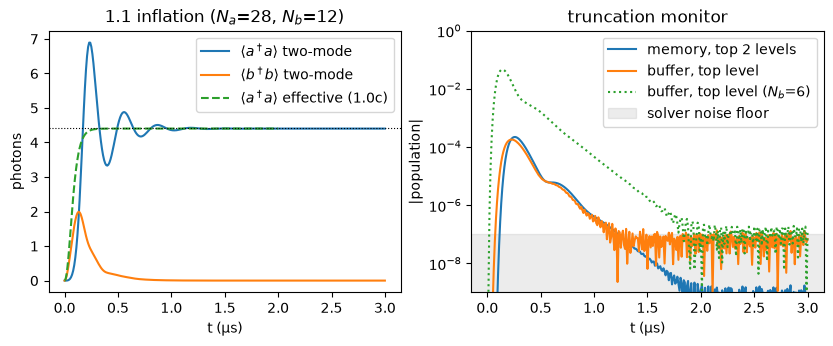

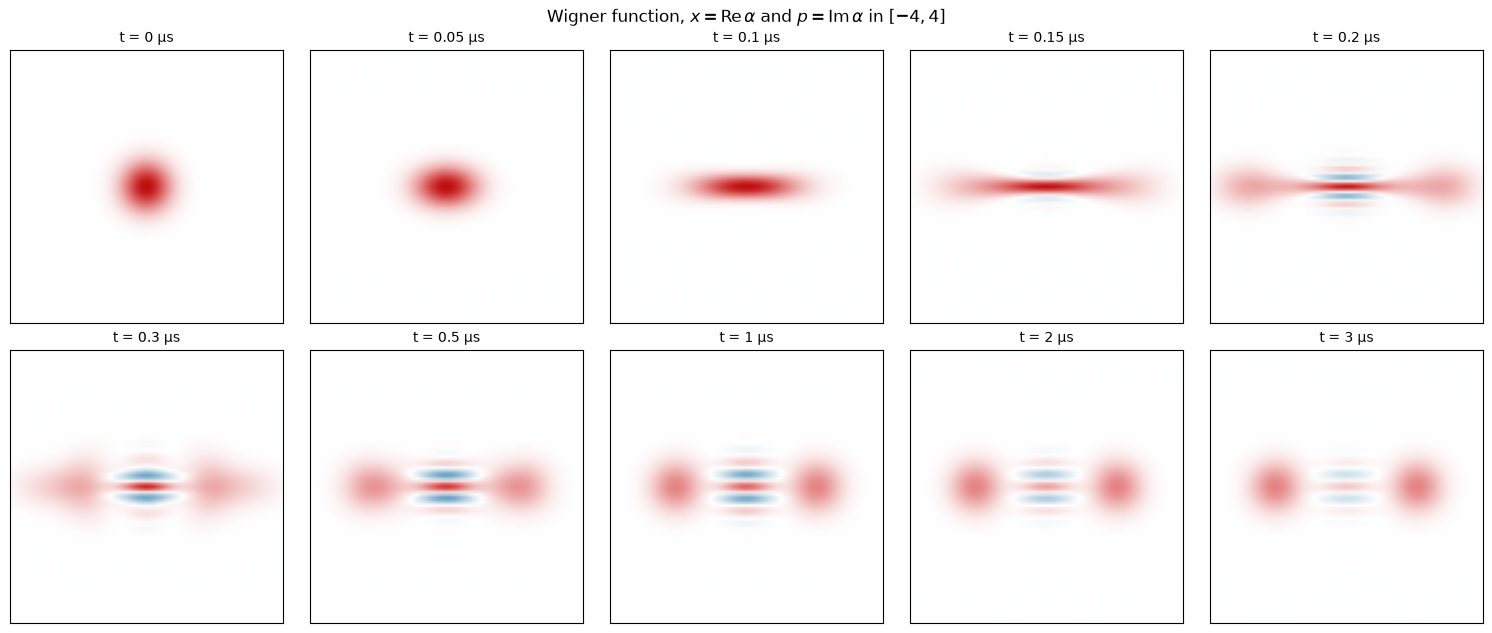

In [10]:
res_1 = inflate(NA_C, NB_C, P, t_1)
na_1, nb_1 = real(res_1.expects)
rho_1 = memory_state(res_1.states, NA_C, NB_C)
top_a_1 = real(top_level_population(res_1.states, (NA_C, NB_C), 0, 2))
top_b_1 = real(top_level_population(res_1.states, (NA_C, NB_C), 1, 1))
outside_band = np.nonzero(np.abs(na_1 - ALPHA2) > 0.01 * ALPHA2)[0]
settled = float(t_1[outside_band[-1] + 1])  # first time after which <n_a> never leaves the 1% band
print(f"peak <a^dag a> = {na_1.max():.3f} at t = {float(t_1[na_1.argmax()]) * 1e3:.0f} ns")
print(f"<a^dag a> stays within 1% of alpha^2 from t = {settled:.2f} us; <a^dag a>(3 us) = {na_1[-1]:.4f}")
print(f"peak <b^dag b> = {nb_1.max():.3f} at t = {float(t_1[nb_1.argmax()]) * 1e3:.0f} ns, <b^dag b>(3 us) = {nb_1[-1]:.1e}")
print(f"max top-2 memory population = {top_a_1.max():.1e}, max top buffer population = {top_b_1.max():.1e}")
g2_ratio, eps_ratio = P.adiabatic_ratios()
print(f"adiabatic condition: g2/kappa_b = {g2_ratio:.3f}, eps_d/kappa_b = {eps_ratio:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(t_1, na_1, label=r"$\langle a^\dagger a\rangle$ two-mode")
axes[0].plot(t_1, nb_1, label=r"$\langle b^\dagger b\rangle$ two-mode")
axes[0].plot(t_c, n_eff_nominal, "--", label=r"$\langle a^\dagger a\rangle$ effective (1.0c)")
axes[0].axhline(ALPHA2, ls=":", c="k", lw=0.8)
axes[0].set(xlabel="t (µs)", ylabel="photons", title=f"1.1 inflation ($N_a$={NA_C}, $N_b$={NB_C})")
axes[0].legend()
# |value|: below ~1e-7 the monitor is ODE noise around zero (both signs), not population.
axes[1].semilogy(t_1, np.abs(top_a_1), label="memory, top 2 levels")
axes[1].semilogy(t_1, np.abs(top_b_1), label="buffer, top level")
axes[1].semilogy(t_1, np.abs(top_b_s), ":", label="buffer, top level ($N_b$=6)")
axes[1].axhspan(1e-9, 1e-7, color="gray", alpha=0.15, label="solver noise floor")
axes[1].set(xlabel="t (µs)", ylabel="|population|", title="truncation monitor", ylim=(1e-9, 1))
axes[1].legend()
save(fig, "1_1_inflation")
plt.show()

snapshot_times = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 1.0, 2.0, 3.0]
wigner_snapshots(rho_1, t_1, snapshot_times, "1_1_wigner", nrows=2)

**Two-mode vs effective model.** The effective model (dashed) rises monotonically and is within
10% of $\alpha^2$ by 150 ns. The two-mode model instead **overshoots to 6.89 photons (56% above
$\alpha^2$) at 230 ns**, rings down, and only stays within 1% of $\alpha^2$ after 1.07 µs. The buffer peaks at
2.0 photons at 130 ns and then empties to $2\times10^{-5}$. The Wigner snapshots show the vacuum blob
stretching along $x$, splitting into two blobs at $\pm\alpha$, and developing fringes between them.

**Why:** adiabatic elimination assumes the buffer is fast compared with everything it exchanges
energy with, $\kappa_b \gg g_2, \epsilon_d$. Here $g_2/\kappa_b = 0.29$ (marginal) and
$\epsilon_d/\kappa_b = 1.29$, so **the condition is violated by the drive.** Starting from vacuum, the drive
fills the buffer faster than it can decay, so the buffer stores a transient population of about 2 photons. The
pair exchange $g_2\hat a^2\hat b^\dagger$ then converts it into memory photons *coherently*, which is an
underdamped exchange between two modes rather than the instantaneous dissipation the effective model
assumes. That stored energy is what overshoots and rings. Once the memory sits near $\pm\alpha$, the
drive and the pair conversion cancel in the buffer ($g_2\alpha^2 = \epsilon_d$), the buffer empties, and both
models agree on the steady state.

## Task 1.3(a): what state did we prepare?

**Analytic argument.** Every term of $\hat H_{2\mathrm{ph}}$ changes the memory photon number by 0
or ±2 ($\hat a^2\hat b^\dagger$, $\hat a^{\dagger 2}\hat b$, $\hat b$, $\hat b^\dagger$), and the jump
$\sqrt{\kappa_b}\,\hat b$ does not touch the memory. So the memory parity $\hat P = e^{i\pi\hat a^\dagger\hat a}$
commutes with everything except the jump $\sqrt{\kappa_a}\,\hat a$. The vacuum has $\langle\hat P\rangle = +1$.
With $\kappa_a = 0$ the state must stay in the even subspace, and the only even state in the cat
manifold is $|\mathcal C_+\rangle$. With $\kappa_a \ne 0$, each lost photon flips parity, at rate
$\kappa_a\langle n\rangle \approx \kappa_a\alpha^2$, so $\langle\hat P\rangle$ decays at $2\kappa_a\alpha^2$.

We run to 6 µs (three phase-flip times) and track $\langle\hat P\rangle$, the fidelity with
$|\mathcal C_+\rangle$ and with $|{+\alpha}\rangle$, the purity, and the **cat coherence**
$2\,\mathrm{Re}\langle\alpha|\rho_a|{-\alpha}\rangle$. That last quantity is the interference term the Wigner
fringes show: $+1$ for $|\mathcal C_+\rangle$, $0$ for the classical mixture of $|\pm\alpha\rangle$.

kappa_a = 0 control: max |<P> - 1| over 6 us = 2.4e-15
fitted decay of cat coherence = 0.5126 /us
fitted decay of parity        = 0.5132 /us
prediction 2 kappa_a alpha^2   = 0.5154 /us  ->  superposition lifetime 1/Gamma = 1.95 us
t = 1 us: <P> = 0.629, F(C+) = 0.811, F(+alpha) = 0.498, purity = 0.692, coherence = 0.626
t = 3 us: <P> = 0.225, F(C+) = 0.612, F(+alpha) = 0.500, purity = 0.525, coherence = 0.225
t = 6 us: <P> = 0.048, F(C+) = 0.524, F(+alpha) = 0.500, purity = 0.501, coherence = 0.048


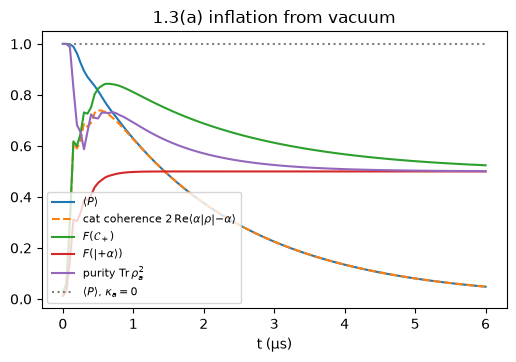

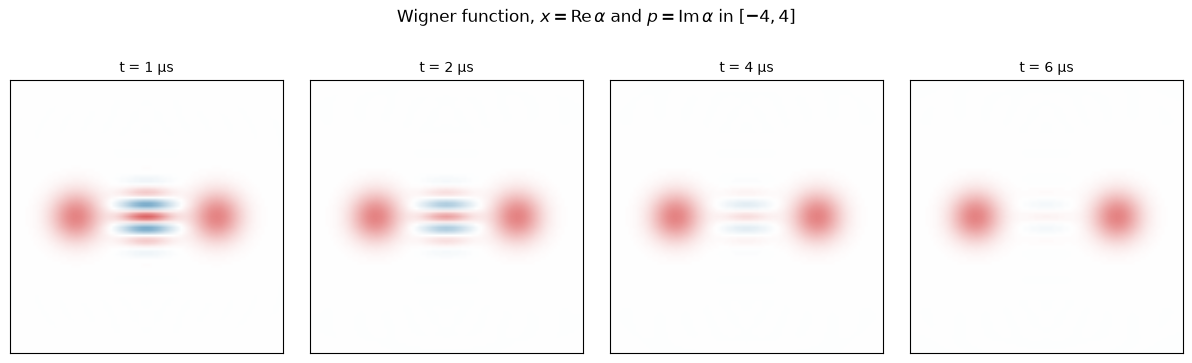

Liouvillian, (N_a, N_b) = (24, 6): Gamma = 0.514559 /us, lifetime 1.9434 us


Liouvillian, (N_a, N_b) = (28, 8): Gamma = 0.514559 /us, lifetime 1.9434 us


Liouvillian, (N_a, N_b) = (32, 10): Gamma = 0.514559 /us, lifetime 1.9434 us


In [11]:
t_3 = jnp.linspace(0.0, 6.0, 121)
res_3 = inflate(NA_C, NB_C, P, t_3)
rho_3 = memory_state(res_3.states, NA_C, NB_C)
parity_3 = real(parity_expectation(rho_3))
coherence_3 = real(cat_coherence(rho_3, P.alpha))
fid_cat_3 = real(fidelity_with(rho_3, cat_state(NA_C, P.alpha, +1)))
fid_plus_3 = real(fidelity_with(rho_3, dq.coherent(NA_C, P.alpha)))
purity_3 = real(purity(rho_3))

control = inflate(NA_C, NB_C, lossless, t_3)
parity_ctrl = real(parity_expectation(memory_state(control.states, NA_C, NB_C)))
print(f"kappa_a = 0 control: max |<P> - 1| over 6 us = {np.max(np.abs(parity_ctrl - 1)):.1e}")

late = np.asarray(t_3) >= 2.0
gamma_coh = fit_decay_rate(np.asarray(t_3)[late], coherence_3[late])
gamma_par = fit_decay_rate(np.asarray(t_3)[late], parity_3[late])
gamma_pred = 2 * P.kappa_a * ALPHA2
print(f"fitted decay of cat coherence = {gamma_coh:.4f} /us")
print(f"fitted decay of parity        = {gamma_par:.4f} /us")
print(f"prediction 2 kappa_a alpha^2   = {gamma_pred:.4f} /us  ->  superposition lifetime 1/Gamma = {1 / gamma_coh:.2f} us")
at = {s: int(np.argmin(np.abs(np.asarray(t_3) - s))) for s in (1.0, 3.0, 6.0)}
for s, i in at.items():
    print(f"t = {s:.0f} us: <P> = {parity_3[i]:.3f}, F(C+) = {fid_cat_3[i]:.3f}, F(+alpha) = {fid_plus_3[i]:.3f}, "
          f"purity = {purity_3[i]:.3f}, coherence = {coherence_3[i]:.3f}")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(t_3, parity_3, label=r"$\langle P\rangle$")
ax.plot(t_3, coherence_3, "--", label=r"cat coherence $2\,\mathrm{Re}\langle\alpha|\rho|{-\alpha}\rangle$")
ax.plot(t_3, fid_cat_3, label=r"$F(\mathcal{C}_+)$")
ax.plot(t_3, fid_plus_3, label=r"$F(|{+\alpha}\rangle)$")
ax.plot(t_3, purity_3, label=r"purity $\mathrm{Tr}\,\rho_a^2$")
ax.plot(t_3, parity_ctrl, ":", c="gray", label=r"$\langle P\rangle$, $\kappa_a = 0$")
ax.set(xlabel="t (µs)", title="1.3(a) inflation from vacuum")
ax.legend(fontsize=8)
save(fig, "1_3a_observables")
plt.show()

wigner_snapshots(rho_3, t_3, [1.0, 2.0, 4.0, 6.0], "1_3a_fringes")

# Independent check of the lifetime, with no fit window: the slowest decay rate of the
# even-parity sector of the Liouvillian, at three truncations.
for na_l, nb_l in [(24, 6), (28, 8), (32, 10)]:
    gamma_eig = phase_flip_rate(P, FockTruncation(na_l, nb_l))
    print(f"Liouvillian, (N_a, N_b) = ({na_l}, {nb_l}): Gamma = {gamma_eig:.6f} /us, lifetime {1 / gamma_eig:.4f} us")

**We prepared the even cat $|\mathcal C_+\rangle$, and it is a superposition, not a mixture.** The evidence:

- **Parity is conserved without $\kappa_a$.** In the $\kappa_a = 0$ control, $\langle\hat P\rangle$ stays at 1 to
  $2\times10^{-15}$ over 6 µs, as the analytic argument requires.
- **It is not a codeword.** The fidelity with $|{+\alpha}\rangle$ is exactly 0.500 at all times: the state is
  symmetric under $\alpha\to-\alpha$.
- **Superposition vs mixture.** Both a cat and a mixture give $F(|{+\alpha}\rangle) = 1/2$, so that alone cannot
  tell them apart. The cat coherence can: it is 0.63 at 1 µs (a mixture would give 0) and decays to
  0.05 by 6 µs. The purity falls from 0.69 to 0.50, the value for an equal two-state mixture, and the
  Wigner fringes fade in step.
- **How long it stays a superposition.** The cat coherence and the parity decay at the same fitted rate,
  0.513 /µs. That matches the predicted phase-flip rate $2\kappa_a\alpha^2 = 0.515$ /µs to 0.5%, so the superposition
  lifetime is **1.95 µs**. The fit uses 2–6 µs only, so we check it without any fit: the slowest decay rate
  of the even-parity sector of the full two-mode Liouvillian is 0.5146 /µs (**1.943 µs**), unchanged to $10^{-7}$
  between $(N_a, N_b) = (24, 6)$ and $(32, 10)$. The fit agrees with it to 0.3%. It is not fully pure even at 1 µs ($\langle P\rangle = 0.63$) because phase flips start
  during the inflation itself, when the memory holds up to 6.9 photons.
- **The early dip in purity** (to about 0.6 near 0.3 µs) is memory–buffer *entanglement*, not phase flips:
  while the buffer is populated, the reduced memory state is mixed. It recovers as the buffer
  empties, and then the slow phase-flip decay takes over.

   prepared state, t = 1 us: F(+alpha) = 0.498, <n> = 4.36, <P> = +0.629, coherence = +0.626, purity = 0.692
 equal mixture of |+-alpha>: F(+alpha) = 0.500, <n> = 4.41, <P> = +0.000, coherence = +0.000, purity = 0.500


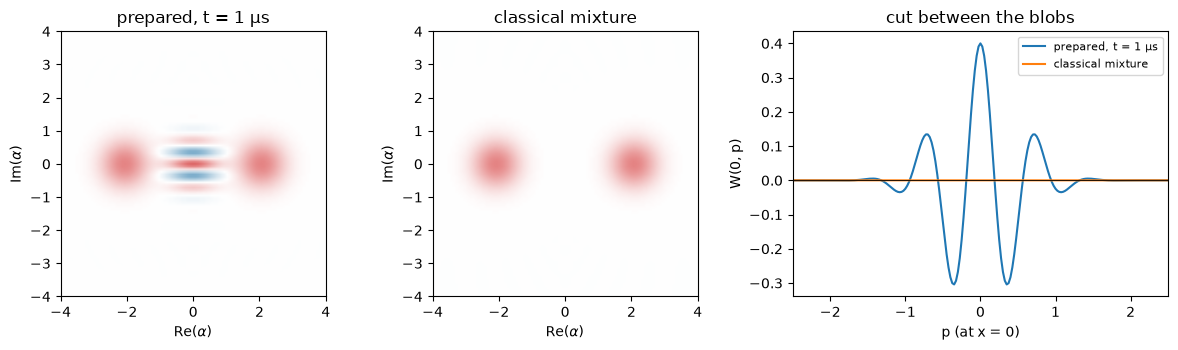

In [12]:
# Superposition vs mixture: same codeword populations, different state.
t_cmp = 1.0
rho_cat = rho_3[int(np.argmin(np.abs(np.asarray(t_3) - t_cmp)))]
plus_dm = dq.coherent(NA_C, P.alpha).todm()
minus_dm = dq.coherent(NA_C, -P.alpha).todm()
mixture = 0.5 * (plus_dm + minus_dm)
for name, state in (("prepared state, t = 1 us", rho_cat), ("equal mixture of |+-alpha>", mixture)):
    print(f"{name:>27}: F(+alpha) = {float(fidelity_with(state, dq.coherent(NA_C, P.alpha))):.3f}, "
          f"<n> = {float(real(dq.expect(dq.number(NA_C), state))):.2f}, <P> = {float(parity_expectation(state)):+.3f}, "
          f"coherence = {float(cat_coherence(state, P.alpha)):+.3f}, purity = {float(purity(state)):.3f}")

XMAX = 4.0
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, state, title in ((axes[0], rho_cat, "prepared, t = 1 µs"), (axes[1], mixture, "classical mixture")):
    dq.plot.wigner(state, ax=ax, xmax=XMAX, colorbar=False)
    ax.set_title(title)
for state, label in ((rho_cat, "prepared, t = 1 µs"), (mixture, "classical mixture")):
    xs, ps, W = dq.wigner(state, xmax=XMAX, ymax=XMAX, npixels=321)
    ix = int(np.argmin(np.abs(np.asarray(xs))))
    axes[2].plot(np.asarray(ps), real(W)[ix, :], label=label)  # dq.wigner is indexed [x, p]
axes[2].axhline(0, c="k", lw=0.6)
axes[2].set(xlabel="p (at x = 0)", ylabel="W(0, p)", title="cut between the blobs", xlim=(-2.5, 2.5))
axes[2].legend(fontsize=8)
fig.tight_layout()
save(fig, "1_3a_superposition_vs_mixture")
plt.show()

The two states agree on everything a measurement in the codeword basis can see, $F(|{+\alpha}\rangle)$ and
$\langle n\rangle$, but not on the interference term. The prepared state has fringes that go **negative**
(no classical probability distribution can do that), while the mixture's cut is flat at zero. The fringe
at the origin is the parity itself, since $W(0,0) = \tfrac{2}{\pi}\langle\hat P\rangle$.

## Task 1.3(b): preparing $|0_L\rangle = |{+\alpha}\rangle$

Inflation from vacuum is symmetric under $\alpha \to -\alpha$, and the stabilization conserves parity, so it
can never pick a well by itself. Something has to break the symmetry. Near the origin, the two-photon drive
**anti-squeezes** along $x$: it amplifies any offset along $x$ exponentially (the vacuum blob stretching
along $x$ in the Task 1.1 Wigner frames). So we only need a small push in the $+x$ direction *before or
during* that amplification. We test two ways to deliver it, both with a resonant memory drive
$\hat H_d(t) = \varepsilon(t)\, i(e^{i\theta}\hat a^\dagger - e^{-i\theta}\hat a)$, which on its own displaces
the memory by $\int\varepsilon\,dt \cdot e^{i\theta}$:

- **A: displaced start.** Drive first, with the stabilization off, to reach $|\beta\rangle$. Then inflate.
- **B: bias pulse during inflation.** Switch the stabilization on from vacuum as in Task 1.1, and apply a
  short square pulse of area $A = \varepsilon T$ during the first $T$ nanoseconds.

### Method A: displaced start

beta = 0.00: F(+alpha) = 0.5000, basin model = 0.5000, Re<a> = 0.000


beta = 0.25: F(+alpha) = 0.6931, basin model = 0.6915, Re<a> = 0.810


beta = 0.50: F(+alpha) = 0.8436, basin model = 0.8413, Re<a> = 1.442


beta = 0.75: F(+alpha) = 0.9351, basin model = 0.9332, Re<a> = 1.826


beta = 1.00: F(+alpha) = 0.9783, basin model = 0.9772, Re<a> = 2.007


beta = 1.25: F(+alpha) = 0.9942, basin model = 0.9938, Re<a> = 2.074


beta = 1.50: F(+alpha) = 0.9988, basin model = 0.9987, Re<a> = 2.093


beta = 2.00: F(+alpha) = 1.0000, basin model = 1.0000, Re<a> = 2.098


phase error  0.0 deg: F(+alpha) = 0.9988, basin model = 0.9987
phase error 22.5 deg: F(+alpha) = 0.9946, basin model = 0.9972
phase error 45.0 deg: F(+alpha) = 0.9573, basin model = 0.9831
phase error 67.5 deg: F(+alpha) = 0.8057, basin model = 0.8745
phase error 90.0 deg: F(+alpha) = 0.5000, basin model = 0.5000
max truncation-monitor population over method A runs: 1.8e-04


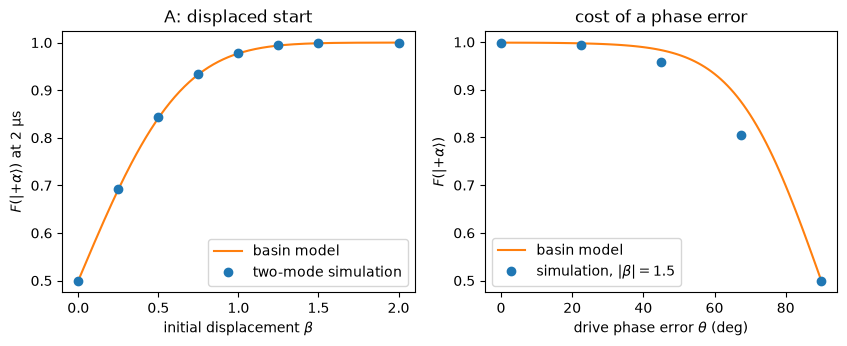

In [13]:
BETAS = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0]
t_p = jnp.linspace(0.0, 2.0, 21)
a_c, _ = dq.destroy(NA_C, NB_C)
plus_c = dq.coherent(NA_C, P.alpha)


def prepare(memory0=None, extra_H=None, save_states=False, tsave=None):
    tsave = t_p if tsave is None else tsave
    res = inflate(NA_C, NB_C, P, tsave, memory0=memory0, extra_H=extra_H,
                  extra_exp_ops=[a_c, *MONITORS], save_states=save_states)
    rho_end = memory_state(res.final_state, NA_C, NB_C)
    _, _, re_a, top_a, top_b = real(res.expects)
    return {"fidelity": float(fidelity_with(rho_end, plus_c)), "re_a": float(re_a[-1]),
            "top": max(top_a.max(), top_b.max()), "rho": rho_end, "res": res}


MONITORS = [top_level_projector((NA_C, NB_C), 0, 2), top_level_projector((NA_C, NB_C), 1, 1)]
prep = []
for beta in BETAS:
    prep.append({"beta": beta, **prepare(memory0=dq.coherent(NA_C, beta))})
    print(f"beta = {beta:4.2f}: F(+alpha) = {prep[-1]['fidelity']:.4f}, "
          f"basin model = {basin_fidelity(beta):.4f}, Re<a> = {prep[-1]['re_a']:.3f}")

# Cost of a drive-phase error: start at 1.5 e^{i theta}.
THETAS = [0.0, math.pi / 8, math.pi / 4, 3 * math.pi / 8, math.pi / 2]
phase_err = [prepare(memory0=dq.coherent(NA_C, 1.5 * np.exp(1j * th)))["fidelity"] for th in THETAS]
for th, f in zip(THETAS, phase_err):
    print(f"phase error {math.degrees(th):4.1f} deg: F(+alpha) = {f:.4f}, basin model = {basin_fidelity(1.5, th):.4f}")
print(f"max truncation-monitor population over method A runs: {max(p['top'] for p in prep):.1e}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
beta_fine = np.linspace(0, 2, 200)
axes[0].plot(beta_fine, [basin_fidelity(b) for b in beta_fine], "-", c="C1", label="basin model")
axes[0].plot(BETAS, [p["fidelity"] for p in prep], "o", c="C0", label="two-mode simulation")
axes[0].set(xlabel=r"initial displacement $\beta$", ylabel=r"$F(|{+\alpha}\rangle)$ at 2 µs", title="A: displaced start")
axes[0].legend()
th_fine = np.linspace(0, math.pi / 2, 100)
axes[1].plot(np.degrees(th_fine), [basin_fidelity(1.5, t) for t in th_fine], "-", c="C1", label="basin model")
axes[1].plot(np.degrees(THETAS), phase_err, "o", c="C0", label=r"simulation, $|\beta| = 1.5$")
axes[1].set(xlabel=r"drive phase error $\theta$ (deg)", ylabel=r"$F(|{+\alpha}\rangle)$", title="cost of a phase error")
axes[1].legend()
save(fig, "1_3b_fidelity_vs_beta")
plt.show()

**Method A works, and a one-line model predicts it.** The fidelity rises from 0.50 to **0.978 at
$\beta = 1$** and **0.9988 at $\beta = 1.5$**. The **basin model** says the stabilization sends each half of phase
space to its nearer valley, so the error is the part of $|\beta\rangle$ with $x < 0$. The $x$-quadrature of
$|\beta\rangle$ is Gaussian with mean $\beta\cos\theta$ and variance 1/4, so
$$F \approx 1 - \tfrac12\,\mathrm{erfc}\!\left(\sqrt2\,\beta\cos\theta\right).$$
It matches every point of the $\beta$ sweep to within 0.003 with **no free parameters**.

**For phase errors the model is only an upper bound.** A phase error costs more than shrinking the
push to $\beta\cos\theta$: at $|\beta| = 1.5$ the error grows from 0.0012 to 0.005 at 22.5° and to **0.043 at 45°**
(the model says 0.017), and at 90° there is no information at all ($F = 0.5$). The $p$ part of the push is not
neutral. The stabilization squeezes $p$, so it draws that part of the state back toward the unstable point
at the origin, where vacuum noise splits it again. The effective model shows the same excess (0.971 at
45°), so this is generic to the stabilization; the two-mode buffer adds a little more.

### Method B: bias pulse during inflation

T =  10 ns | F(+alpha) for areas [0.25, 0.5, 1.0, 1.5, 2.5, 4.0]: 0.6925 0.8428 0.9780 0.9987 0.9998 0.9542  (drive up to 64 MHz)


T =  50 ns | F(+alpha) for areas [0.25, 0.5, 1.0, 1.5, 2.5, 4.0]: 0.6802 0.8255 0.9695 0.9974 0.9985 0.9376  (drive up to 13 MHz)


T = 100 ns | F(+alpha) for areas [0.25, 0.5, 1.0, 1.5, 2.5, 4.0]: 0.6523 0.7831 0.9411 0.9897 0.9934 0.9181  (drive up to 6 MHz)
max truncation-monitor population over method B runs: 2.5e-03
chosen pulse: A = 2.5, T = 50 ns, eps/2pi = 8.0 MHz -> F(+alpha) = 0.9985, Re<a> = 2.092


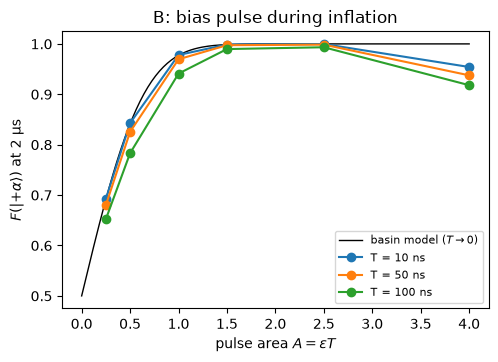

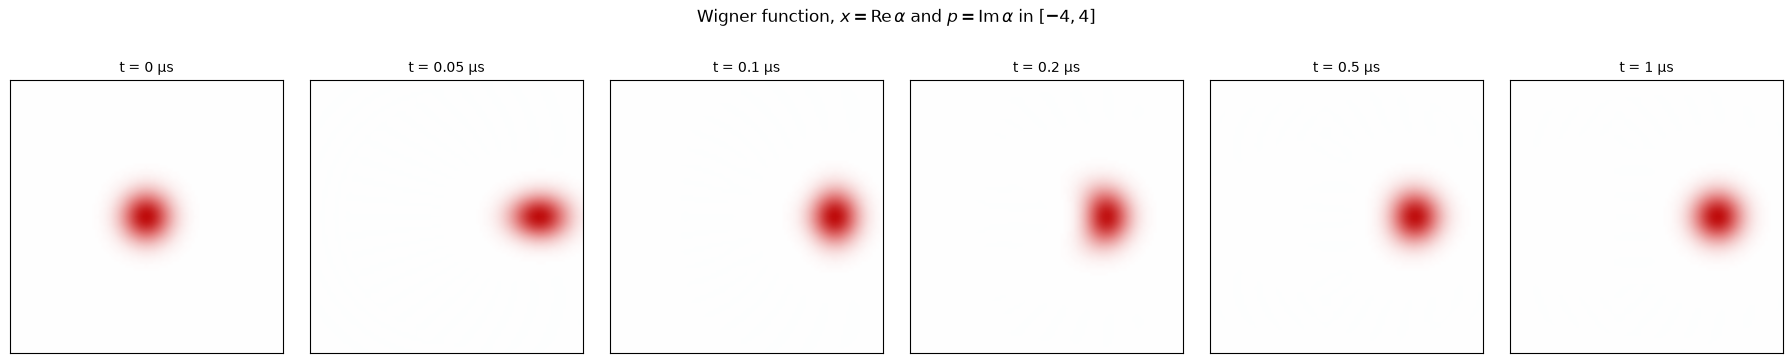

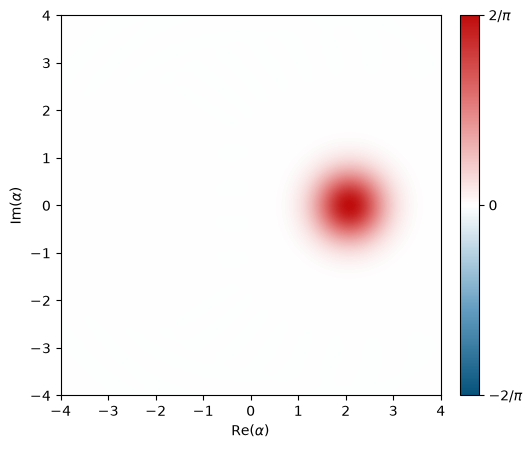

In [14]:
AREAS = [0.25, 0.5, 1.0, 1.5, 2.5, 4.0]
DURATIONS = [0.01, 0.05, 0.1]  # us
pulse_runs = {}
for T in DURATIONS:
    for A in AREAS:
        pulse_runs[(T, A)] = prepare(extra_H=bias_pulse(NA_C, NB_C, area=A, duration=T))
    row = " ".join(f"{pulse_runs[(T, A)]['fidelity']:.4f}" for A in AREAS)
    peak_mhz = max(AREAS) / T / (2 * math.pi)
    print(f"T = {T * 1e3:3.0f} ns | F(+alpha) for areas {AREAS}: {row}  (drive up to {peak_mhz:.0f} MHz)")
print(f"max truncation-monitor population over method B runs: {max(r['top'] for r in pulse_runs.values()):.1e}")

BEST_B = (0.05, 2.5)
best_b = pulse_runs[BEST_B]
print(f"chosen pulse: A = {BEST_B[1]}, T = {BEST_B[0] * 1e3:.0f} ns, eps/2pi = {BEST_B[1] / BEST_B[0] / (2 * math.pi):.1f} MHz"
      f" -> F(+alpha) = {best_b['fidelity']:.4f}, Re<a> = {best_b['re_a']:.3f}")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
area_fine = np.linspace(0, 4, 200)
ax.plot(area_fine, [basin_fidelity(x) for x in area_fine], "-", c="k", lw=1, label=r"basin model ($T \to 0$)")
for i, T in enumerate(DURATIONS):
    ax.plot(AREAS, [pulse_runs[(T, A)]["fidelity"] for A in AREAS], "o-", c=f"C{i}", label=f"T = {T * 1e3:.0f} ns")
ax.set(xlabel=r"pulse area $A = \varepsilon T$", ylabel=r"$F(|{+\alpha}\rangle)$ at 2 µs", title="B: bias pulse during inflation")
ax.legend(fontsize=8)
save(fig, "1_3b_pulse_area")
plt.show()

t_w = jnp.linspace(0.0, 1.0, 101)
res_w = inflate(NA_C, NB_C, P, t_w, extra_H=bias_pulse(NA_C, NB_C, area=BEST_B[1], duration=BEST_B[0]))
wigner_snapshots(memory_state(res_w.states, NA_C, NB_C), t_w, [0.0, 0.05, 0.1, 0.2, 0.5, 1.0], "1_3b_pulse_wigner")
dq.plot.wigner(best_b["rho"], xmax=4)
save(plt.gcf(), "1_3b_prepared_state")
plt.show()

**Method B also works: 0.998 with a 50 ns pulse of area 2.5,** with no need to switch the stabilization off.
The sweep shows three things:

- **Short pulses are a displaced start.** At $T = 10$ ns every point up to $A = 2.5$ sits on the basin-model
  curve, with $\beta$ replaced by the area $A$: the pulse is over before the stabilization has done anything.
- **Longer pulses at the same area do worse.** A push that arrives after the anti-squeezing has begun
  competes with vacuum noise that has already been amplified, so it is worth less.
- **Too much is worse than enough, for both methods.** At $A = 4$ the fidelity drops to 0.95 for every
  duration, and a displaced start at $\beta = 4$ drops the same way (next cell). The memory then starts with
  about 16 photons, far outside the $+\alpha$ well.

### Is the overdrive real?

Two possible artefacts: truncation (the $A = 4$ runs had up to $3\times10^{-3}$ in the top memory levels at
$N_a = 28$), and the model. We rerun at $N_a = 40$, and repeat in the effective single-mode model.

In [15]:
na_big = 40
mon_big = [top_level_projector((na_big, NB_C), 0, 2), top_level_projector((na_big, NB_C), 1, 1)]
checks = {
    "pulse A = 4, T = 10 ns": {"extra_H": bias_pulse(na_big, NB_C, area=4.0, duration=0.01)},
    "displaced start beta = 4": {"memory0": dq.coherent(na_big, 4.0)},
}
for label, kw in checks.items():
    r = inflate(na_big, NB_C, P, t_p, extra_exp_ops=mon_big, save_states=False, **kw)
    f = float(fidelity_with(memory_state(r.final_state, na_big, NB_C), dq.coherent(na_big, P.alpha)))
    _, _, ta, tb = real(r.expects)
    print(f"two-mode, N_a = {na_big}, {label}: F(+alpha) = {f:.4f}  (top-level monitor max {max(ta.max(), tb.max()):.1e})")

m_eff = effective_model(na_big, P)
for label, beta in (("beta = 4", 4.0), ("|beta| = 1.5 at 45 deg", 1.5 * np.exp(1j * math.pi / 4))):
    r = dq.mesolve(m_eff.H, m_eff.jump_ops, dq.coherent(na_big, beta), t_p, method=METHOD, progress_meter=False)
    f = float(fidelity_with(r.final_state, dq.coherent(na_big, P.alpha)))
    print(f"effective model, {label}: F(+alpha) = {f:.4f}  (basin model {basin_fidelity(abs(beta), float(np.angle(beta))):.4f})")

two-mode, N_a = 40, pulse A = 4, T = 10 ns: F(+alpha) = 0.9551  (top-level monitor max 2.5e-05)


two-mode, N_a = 40, displaced start beta = 4: F(+alpha) = 0.9559  (top-level monitor max 2.6e-05)


effective model, beta = 4: F(+alpha) = 1.0000  (basin model 1.0000)


effective model, |beta| = 1.5 at 45 deg: F(+alpha) = 0.9711  (basin model 0.9831)


At $N_a = 40$ the fidelities agree with $N_a = 28$ to 0.001, with the monitor below $3\times10^{-5}$, so this is
**not truncation**. In the effective model a start at $\beta = 4$ gives $F = 1.000$, so it is **not generic**
either: it is the two-mode physics of Task 1.1 again. A memory holding 16 photons dumps photon pairs into
the buffer faster than $\kappa_b$ can remove them ($\epsilon_d/\kappa_b$ is already 1.3 at the target), and the
buffer converts them back coherently. The state rings inward through the ridge and part of it lands in
the $-\alpha$ well. **The useful push is about $\alpha$:** big enough to beat vacuum noise, small enough not to
overload the buffer.

### Method B: cost of a phase error

Method A loses 0.043 at a 45° phase error. We run the best pulse of method B at the same angles.

In [16]:
b_phase = [prepare(extra_H=bias_pulse(NA_C, NB_C, area=BEST_B[1], duration=BEST_B[0], theta=th))["fidelity"]
           for th in THETAS[:3]]
for th, fa, fb in zip(THETAS[:3], phase_err, b_phase):
    print(f"phase error {math.degrees(th):4.1f} deg: error A = {1 - fa:.2e}, error B = {1 - fb:.2e}")

phase error  0.0 deg: error A = 1.22e-03, error B = 1.46e-03
phase error 22.5 deg: error A = 5.45e-03, error B = 4.26e-03
phase error 45.0 deg: error A = 4.27e-02, error B = 1.27e-02


**Method B is less sensitive to the phase than method A**: the error grows from 0.0015 to 0.004 at 22.5° and
0.013 at 45° (method A: 0.043). A likely reason: the push lands while the stabilization is already squeezing $p$,
so the $p$ part of a mis-phased push is damped before it can draw the state back to the origin.

### Why method B needs a drive of 10 $g_2$: a linear-amplifier model

The basin model treats the push as instantaneous. To say what a push *during* the inflation is worth, we
linearize the stabilization near vacuum. There the term $g_2 a^2 b^\dagger$ is a degenerate parametric
amplifier: the memory $x$-quadrature grows at
$$\lambda(t) = 2 g_2\,b(t) - \kappa_a/2,$$
where the buffer field $b(t)$ relaxes toward $2\varepsilon_d(t)/\kappa_b$ at rate $\kappa_b/2$ (it fills in about
$2/\kappa_b \approx 120$ ns). A push $\varepsilon(s)$ at time $s$ is amplified like the vacuum noise it competes with, but
only from time $s$ on, so it is worth $\varepsilon(s)\,e^{-\Lambda(s)}$ of displacement at $t = 0$, with $\Lambda(s) = \int_0^s\lambda$:
$$\beta_\mathrm{eff} = \int_0^\infty \varepsilon(s)\, e^{-\Lambda(s)}\, ds, \qquad F \approx 1 - \tfrac12\,\mathrm{erfc}\!\left(\sqrt2\,\beta_\mathrm{eff}\right).$$
It has **no free parameters**, and for a pulse much shorter than $1/\lambda$ it reduces to the basin model
($\beta_\mathrm{eff}$ = area). We check it against every method B run with a small push, where the
linearization holds.

In [17]:
def square(strength, duration):
    return lambda s: strength if s < duration else 0.0


def stabilization_on(s):
    return P.eps_d


print(f"growth rate with the stabilization on: lambda = kappa_2 alpha^2 = {P.kappa2 * ALPHA2:.1f} /us")
for T in DURATIONS:
    for A in [0.5, 1.0]:
        beta_eff = amplified_push(square(A / T, T), stabilization_on, T, P)
        print(f"T = {T * 1e3:3.0f} ns, A = {A}: beta_eff = {beta_eff:.3f}, model F = {basin_fidelity(beta_eff):.4f}, "
              f"simulated F = {pulse_runs[(T, A)]['fidelity']:.4f}")

# A weak push held from t = 0 is worth little: by 100 ns the noise is already amplified.
for frac in [0.05, 0.2]:
    beta_eff = amplified_push(square(frac * P.g2, 1.0), stabilization_on, 1.0, P)
    sim = prepare(extra_H=bias_pulse(NA_C, NB_C, area=frac * P.g2, duration=1.0))["fidelity"]
    print(f"weak push {frac} g2 for 1 us: model F = {basin_fidelity(beta_eff):.4f}, simulated F = {sim:.4f}")

growth rate with the stabilization on: lambda = kappa_2 alpha^2 = 24.8 /us
T =  10 ns, A = 0.5: beta_eff = 0.498, model F = 0.8405, simulated F = 0.8428
T =  10 ns, A = 1.0: beta_eff = 0.997, model F = 0.9769, simulated F = 0.9780
T =  50 ns, A = 0.5: beta_eff = 0.464, model F = 0.8235, simulated F = 0.8255
T =  50 ns, A = 1.0: beta_eff = 0.929, model F = 0.9684, simulated F = 0.9695


T = 100 ns, A = 0.5: beta_eff = 0.389, model F = 0.7818, simulated F = 0.7831
T = 100 ns, A = 1.0: beta_eff = 0.778, model F = 0.9402, simulated F = 0.9411


weak push 0.05 g2 for 1 us: model F = 0.5200, simulated F = 0.5216


weak push 0.2 g2 for 1 us: model F = 0.5794, simulated F = 0.5853


**The model matches every small-push run to within 0.003**, including the long pulses that fall below the basin
curve and a weak push held for 1 µs, which fails ($F \approx 0.52$–0.58) whatever its duration. It also explains the
size of method B's drive. With the stabilization on, the noise is amplified at $\lambda = \kappa_2\alpha^2 \approx 25$ /µs, so a push must
deliver its displacement in less than $1/\lambda \approx 40$ ns: $\varepsilon \gtrsim \beta\lambda$, which for $\beta \approx 2$ is about $10\,g_2$. For large pushes
the model overestimates $F$, because it has no overdrive (the push leaves the linear region).

### Method C: a weak push while the stabilization ramps up

The model points to a fix. The amplification rate is set by the buffer drive, so **ramp $\varepsilon_d$ up slowly**
instead of switching it on. While $\lambda$ is small, a weak push is worth almost its full area. We ramp
$\varepsilon_d$ linearly from 0 over $T_r$, hold a constant push $\varepsilon$ for the whole ramp, and choose $\varepsilon$ with the model so that
$\beta_\mathrm{eff} = 1.5$ (the displacement method A is compared at). Nothing is fitted to the simulation.

ramp 0.25 us: push eps = 8.08 rad/us = 1.68 g2 (1.29 MHz) -> F(+alpha) = 0.99908, error 9.2e-04


ramp 0.50 us: push eps = 5.77 rad/us = 1.20 g2 (0.92 MHz) -> F(+alpha) = 0.99943, error 5.7e-04


ramp 1.00 us: push eps = 4.37 rad/us = 0.91 g2 (0.70 MHz) -> F(+alpha) = 0.99943, error 5.7e-04


ramp 2.00 us: push eps = 3.29 rad/us = 0.69 g2 (0.52 MHz) -> F(+alpha) = 0.99878, error 1.2e-03


method C, phase error  0.0 deg: error = 5.75e-04
method C, phase error 22.5 deg: error = 1.89e-03
method C, phase error 45.0 deg: error = 3.67e-02
max truncation-monitor population over method C runs: 1.3e-06


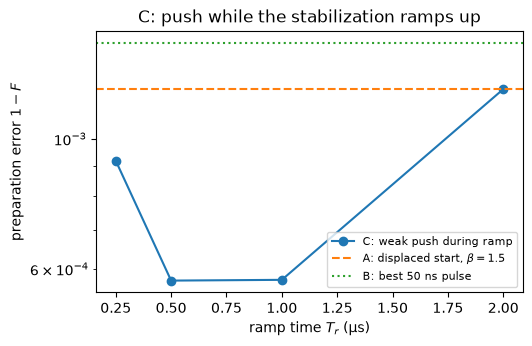

In [18]:
T_RAMPS = [0.25, 0.5, 1.0, 2.0]
T_RAMP = 1.0
runs_c = {}
for T_r in T_RAMPS:
    eps = ramp_push_strength(P, T_r, beta_target=1.5)
    t_grid_c = jnp.linspace(0.0, T_r + 1.5, 26)
    runs_c[T_r] = {"eps": eps, **prepare(extra_H=ramped_preparation(NA_C, NB_C, P, T_r, eps), tsave=t_grid_c)}
    print(f"ramp {T_r:4.2f} us: push eps = {eps:.2f} rad/us = {eps / P.g2:.2f} g2 ({eps / (2 * math.pi):.2f} MHz)"
          f" -> F(+alpha) = {runs_c[T_r]['fidelity']:.5f}, error {1 - runs_c[T_r]['fidelity']:.1e}")

eps_c = runs_c[T_RAMP]["eps"]
t_grid_c = jnp.linspace(0.0, T_RAMP + 1.5, 26)
c_phase = [prepare(extra_H=ramped_preparation(NA_C, NB_C, P, T_RAMP, eps_c, theta=th), tsave=t_grid_c)["fidelity"]
           for th in THETAS[:3]]
for th, f in zip(THETAS[:3], c_phase):
    print(f"method C, phase error {math.degrees(th):4.1f} deg: error = {1 - f:.2e}")
print(f"max truncation-monitor population over method C runs: {max(r['top'] for r in runs_c.values()):.1e}")

fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.semilogy(T_RAMPS, [1 - runs_c[T]["fidelity"] for T in T_RAMPS], "o-", c="C0", label="C: weak push during ramp")
ax.axhline(1 - prep[BETAS.index(1.5)]["fidelity"], c="C1", ls="--", label=r"A: displaced start, $\beta = 1.5$")
ax.axhline(1 - best_b["fidelity"], c="C2", ls=":", label="B: best 50 ns pulse")
ax.set(xlabel=r"ramp time $T_r$ (µs)", ylabel=r"preparation error $1 - F$", title="C: push while the stabilization ramps up")
ax.legend(fontsize=8)
save(fig, "1_3b_method_c")
plt.show()

**Method C reaches error $5.7\times10^{-4}$ with a push of $0.91\,g_2$ (0.70 MHz)**, 11 times weaker than method B's 8 MHz,
and the stabilization is never switched off. That is about half the error of A and B. A shorter ramp needs a
stronger push ($T_r = 0.25$ µs: $1.7\,g_2$, error $9\times10^{-4}$), and a 2 µs ramp is worse again ($1.2\times10^{-3}$). A 0.5 µs ramp
is as good as 1 µs but needs $1.2\,g_2$; we keep 1 µs so the push stays below $g_2$. The phase sensitivity is close to
method A's (0.0019 at 22.5°, 0.037 at 45°), so method C does not relax the phase calibration. The cost is time: the ramp adds about 1 µs to the preparation.

### Check with the circuit terms of the real device

Method B's strong drive was flagged as a risk because the ATS circuit adds terms our model leaves out. Task 2.4a
derived them for the device parameters of Section 2. We add the residual terms (after the pump is retuned to
cancel the Stark shifts): memory Kerr, buffer Kerr $K_b/2\pi = -2.67$ MHz and cross-Kerr $\chi_{ab}/2\pi = -0.20$ MHz.

In [19]:
terms = json.loads(Path("results/task24a/effective_terms.json").read_text())["terms"]
k_a, k_b, chi = (terms[k]["value_rad_per_us"] for k in ("kerr_a", "kerr_b", "chi_ab"))
a_k, b_k = dq.destroy(NA_C, NB_C)
H_circuit = ((k_a / 2) * a_k.dag() @ a_k.dag() @ a_k @ a_k + (k_b / 2) * b_k.dag() @ b_k.dag() @ b_k @ b_k
             + chi * a_k.dag() @ a_k @ b_k.dag() @ b_k)
with_circuit = {
    "A": prepare(memory0=dq.coherent(NA_C, 1.5), extra_H=H_circuit)["fidelity"],
    "B": prepare(extra_H=bias_pulse(NA_C, NB_C, area=BEST_B[1], duration=BEST_B[0]) + H_circuit)["fidelity"],
    "C": prepare(extra_H=ramped_preparation(NA_C, NB_C, P, T_RAMP, eps_c) + H_circuit, tsave=t_grid_c)["fidelity"],
}
without = {"A": prep[BETAS.index(1.5)]["fidelity"], "B": best_b["fidelity"], "C": runs_c[T_RAMP]["fidelity"]}
for m in "ABC":
    print(f"method {m}: error {1 - without[m]:.2e} -> {1 - with_circuit[m]:.2e} with circuit terms")

method A: error 1.22e-03 -> 1.30e-03 with circuit terms
method B: error 1.46e-03 -> 1.32e-03 with circuit terms
method C: error 5.75e-04 -> 7.78e-04 with circuit terms


**All three methods survive the circuit terms**, and method C stays the best: errors become $1.3\times10^{-3}$ (A),
$1.3\times10^{-3}$ (B) and $7.8\times10^{-4}$ (C). The buffer Kerr is the term that matters; the cross-Kerr and memory Kerr
change the errors by less than $10^{-4}$. It also limits method C's target: aiming for a larger $\beta_\mathrm{eff}$ (2.0) is
slightly better in the ideal model but 2× worse with the buffer Kerr, so we keep 1.5. Retuning the push phase does not
compensate the Kerr (tested at ±10° and ±20°).

### Method D: displace exactly onto the codeword

Method A's sweep already hints at something: at $\beta = 2.0$ the fidelity is 1.0000 to four digits. The reason is
exact. Take the memory in $|\alpha\rangle$ and the buffer in vacuum. Then
$$g_2\,\hat a^2\hat b^\dagger|\alpha,0\rangle = g_2\alpha^2|\alpha,1\rangle = \varepsilon_d|\alpha,1\rangle,\qquad
g_2\,\hat a^{\dagger2}\hat b|\alpha,0\rangle = 0,\qquad \hat b|\alpha,0\rangle = 0,$$
so the drive and the pair exchange cancel: $H|\alpha,0\rangle = 0$ and $\hat b|\alpha,0\rangle = 0$. **$|\alpha\rangle|0\rangle$ is a dark state of the full
two-mode stabilization, not only of the one-mode model.** If the memory is displaced to exactly $\beta = \alpha$ with the
pump off, and then the pump and buffer drive are switched on, nothing moves: there is no inflation transient and no
basin to roll into. Only memory loss $\kappa_a$ acts, and the stabilization holds the state near the codeword. We check
the cancellation numerically, then simulate the preparation with the same `prepare` as method A (2 µs, same box).

In [20]:
_, b_c = dq.destroy(NA_C, NB_C)
psi_dark = dq.tensor(dq.coherent(NA_C, P.alpha), dq.fock(NB_C, 0))
H_two_mode = two_mode_model(NA_C, NB_C, P).H
print(f"|H|alpha,0>| = {float(jnp.linalg.norm((H_two_mode @ psi_dark).to_jax())):.1e}, "
      f"|b|alpha,0>| = {float(jnp.linalg.norm((b_c @ psi_dark).to_jax())):.1e}  (N_a = {NA_C}, N_b = {NB_C})")

BETAS_D = [1.8, P.alpha, 2.3, 2.5]
prep_d = {beta: prepare(memory0=dq.coherent(NA_C, beta)) for beta in BETAS_D}
for beta in BETAS_D:
    print(f"method D sweep: beta = {beta:4.2f}: error {1 - prep_d[beta]['fidelity']:.2e}, "
          f"Re<a> = {prep_d[beta]['re_a']:.3f}")
err_d = 1 - prep_d[P.alpha]["fidelity"]

res_d0 = inflate(NA_C, NB_C, lossless, t_p, memory0=dq.coherent(NA_C, P.alpha), save_states=False)
err_d0 = 1 - float(fidelity_with(memory_state(res_d0.final_state, NA_C, NB_C), plus_c))
print(f"method D with kappa_a = 0: error {err_d0:.1e}")

err_d_circuit = 1 - prepare(memory0=dq.coherent(NA_C, P.alpha), extra_H=H_circuit)["fidelity"]
print(f"method D: error {err_d:.2e} -> {err_d_circuit:.2e} with circuit terms")
for scale in (0.9, 1.1):
    e = 1 - prepare(memory0=dq.coherent(NA_C, scale * P.alpha))["fidelity"]
    print(f"method D amplitude {scale:.1f} alpha: error {e:.2e}")
for th in THETAS[1:3]:
    e = 1 - prepare(memory0=dq.coherent(NA_C, P.alpha * np.exp(1j * th)))["fidelity"]
    print(f"method D phase error {math.degrees(th):4.1f} deg: error {e:.2e}")
print(f"method D vs method C: {(1 - runs_c[T_RAMP]['fidelity']) / err_d:.0f}x lower error, "
      f"{(1 - with_circuit['C']) / err_d_circuit:.0f}x lower with circuit terms")

|H|alpha,0>| = 3.2e-05, |b|alpha,0>| = 0.0e+00  (N_a = 28, N_b = 12)


method D sweep: beta = 1.80: error 1.31e-04, Re<a> = 2.098
method D sweep: beta = 2.10: error 8.41e-06, Re<a> = 2.098
method D sweep: beta = 2.30: error 4.63e-05, Re<a> = 2.098
method D sweep: beta = 2.50: error 2.02e-04, Re<a> = 2.097


method D with kappa_a = 0: error 9.3e-12


method D: error 8.41e-06 -> 5.37e-05 with circuit terms


method D amplitude 0.9 alpha: error 5.85e-05


method D amplitude 1.1 alpha: error 5.06e-05


method D phase error 22.5 deg: error 1.69e-03


method D phase error 45.0 deg: error 2.73e-02
method D vs method C: 68x lower error, 14x lower with circuit terms


**Method D is the best preparation we found.** It is method A with the push set exactly to $\beta = \alpha$, and the
dark-state argument says why that is the right push. At $\beta = \alpha$ the error after 2 µs is $8.4\times10^{-6}$,
68× below method C. The sweep has its minimum at $\beta = \alpha$: pushing short (1.8) or long (2.3, 2.5) costs more.
(Method A's own sweep already gives $F = 1.0000$ at $\beta = 2.0$ to four digits; the $\beta = 1.5$ point is the one
we compared A at.) The residual is memory loss: with $\kappa_a = 0$ the error is $9\times10^{-12}$, because
single-photon loss slowly shrinks the coherent state below $\alpha$. The small $\|H|\alpha,0\rangle\|$ is the
truncated memory box, not physics.

With the circuit terms the error is $5.4\times10^{-5}$, 14× below method C, not 68×: the memory Kerr does not vanish
on $|\alpha\rangle$, so the codeword is no longer exactly dark. That is the fair comparison for a real device.
A ±10% amplitude error costs little ($5\times10^{-5}$–$6\times10^{-5}$). The phase matters as much as in method A
($1.7\times10^{-3}$ at 22.5°, $2.7\times10^{-2}$ at 45°), because a rotated coherent state is not dark.

### Comparison

| | A: displaced start | B: bias pulse during inflation | C: weak push during a ramp | D: displace onto the codeword |
|---|---|---|---|---|
| Best error simulated | $1.2\times10^{-3}$ ($\beta = 1.5$) | $1.5\times10^{-3}$ ($A = 2.5$, 50 ns) | $5.7\times10^{-4}$ ($T_r = 1$ µs) | $8.4\times10^{-6}$ ($\beta = \alpha$) |
| With ATS circuit terms (Task 2.4a) | $1.3\times10^{-3}$ | $1.3\times10^{-3}$ | $7.8\times10^{-4}$ | $5.4\times10^{-5}$ |
| Predicted by | basin model, no free parameters | amplifier model (small pushes) | amplifier model sets the push, no fit | exact dark state of the two-mode model |
| Stabilization during the pulse | must be **off** | stays **on** | ramps up, never switched off | off during the push, as A |
| Drive strength needed | gentle: $\varepsilon/2\pi \approx 0.24$ MHz over 1 µs | strong: 8 MHz, about $10\,g_2$ | 0.70 MHz, $0.91\,g_2$ | as A, push to $\beta = \alpha$ |
| Error at 22.5° / 45° phase error | 0.005 / 0.043 | 0.004 / 0.013 | 0.002 / 0.037 | 0.002 / 0.027 |
| Extra time | drive before the pump turns on | none (50 ns) | ~1 µs ramp | as A |
| Failure modes | weak push; overdrive ($\beta = 4$: 0.956) | weak push; overdrive ($A = 4$: 0.954); late push | push too strong for the buffer Kerr | phase error; memory Kerr |

## Task 1.3(c): what does it cost?

- **Which method to use.** Method D: it reaches the lowest error and needs only method A's drive line.
  Its costs are the phase lock and a push with the pump off; if the pump cannot be switched, method C is the
  fallback.
- **An extra control line on the memory.** All four methods need a resonant memory drive, which the bare
  stabilization scheme does not have. The memory is the high-Q mode, so the port must be weakly coupled,
  or it adds loss to $\kappa_a$, and therefore phase flips.
- **Phase calibration.** The drive phase picks *which* codeword you get, and it must be locked to the pump frame
  that defines the real axis. We measured the cost at $|\beta| = 1.5$: the preparation error goes from 0.001 to
  0.005 at 22.5° and 0.043 at 45°, worse than the basin model's $\beta\cos\theta$ estimate. So the phase needs to be
  calibrated to within about 20° for a 99.5% preparation with method A. Method B is the most tolerant (0.013 at 45°);
  method C is close to A (0.037).
- **Interaction with the stabilization.** Method A must sequence the drive *before* the pump and buffer
  drive turn on, which costs switching time and a second calibration (the turn-on transient). Method B
  avoids the switching but needs a drive about 10× stronger than $g_2$, which conflicts with the advice
  (Task 2.3) to keep memory drives well below $g_2$. Method C removes that conflict ($0.91\,g_2$) at the cost of a
  1 µs buffer-drive ramp, which needs an amplitude-controlled buffer drive. With the circuit terms of Task 2.4a
  all four still work; for A, B and C the buffer Kerr is the term that matters, for D the memory Kerr.
- **A tuning window.** Methods A and B fail by overdriving as well as by underdriving: the push must be about
  $\alpha$ (1.5–2.5 here), not "as big as possible". Method B also needs a short pulse, because a late push is
  worth less; the amplifier model says exactly how much less, so methods B and C can be designed instead of scanned.
- **What it does not cost:** the protected qubit. After inflation the state is a codeword, bit flips are
  exponentially suppressed, and the preparation error is set by the overlap with the wrong basin, not by $\kappa_a$.